# Arctic Tern Migration

Arctic Tern (Sterna paradisaea) are a species of seabird and are known to have one of the longest migrations in the world, as they travel from the Arctic to the Antarctic every year. Arctic Tern are affected by the impacts of climate change (Morten et al., 2023). These birds are also culturally significant for indigenous communities, as their eggs are important for subsistence harvesting.

## Research question
> Given that the Arctic is experiencing the effects of climate change at a much faster rate than the rest of the world, where do Arctic Tern spend most of the year and when do they migrate? How much of their year is actually spent at the poles versus actively migrating.

## Load required libraries

In [1]:
### load libraries

### folder/file management
import os
import pathlib

### tabular data
import pandas as pd

### handle geospatial vector data
import geopandas as gpd

### access prepped gbif data
import earthpy as et

### libraries for dynamic mapping
import cartopy.crs as ccrs

### customize the dynamic plot
import panel as pn

### make dynamic plot with geodataframe
import hvplot.pandas
import holoviews as hv

### get month names
import calendar

## Create directory for data

In [2]:
### designate your data directory
data_dir = pathlib.Path("D:\LThomas\earth-data-analytics\data")

### make the path
os.makedirs(data_dir, exist_ok = True)

## Download and plot ecoregions

In [3]:
### get url for ecoregions
ecoreg_url = ("https://storage.googleapis.com/"
       "teow2016/Ecoregions2017.zip")

### name the ecoregions directory name and file name
ecoreg_dir = os.path.join(data_dir, "ecoregions")

### make the ecoregions directory
os.makedirs(ecoreg_dir, exist_ok= True)

### join ecoregions shapefile path
ecoreg_path = os.path.join(ecoreg_dir, "ecoregions.shp")

### download the data once
if not os.path.exists(ecoreg_path):

    ### open file at url
    ecoreg_gdf = gpd.read_file(ecoreg_url)

    ### save it to the filepath we've defined
    ecoreg_gdf.to_file(ecoreg_path)

### open up the ecoregions boundaries
ecoreg_gdf = gpd.read_file(ecoreg_path)

## Load GBIF data
**Species Occurrence Data:** The data we're using comes from the Global Biodiversity Information Facility (GBIF) website (https://www.gbif.org/taxon/6ZSDC), which reports geospatial species occurrence data. Specifically, we're using Arctic Tern data from 2020. 
**Ecoregion Data:** 

In [4]:
### load the GBIF data
gbif_df = pd.read_csv(
    "D:/LThomas/earth-data-analytics/data/gbif/arctic-tern-2020.csv", 

    ### csv delimeter isn't always a comma, in this case it's a tab
    delimiter = '\t',

    ### set unique identifier as index
    index_col = 'gbifID',

    ### subset columns
    usecols = ['gbifID', 'decimalLatitude', 'decimalLongitude', 'month']
)

In [6]:
### convert the dataframe to a geodataframe
gbif_gdf = (
    gpd.GeoDataFrame(
        gbif_df, 

        ### set geometry for geodataframe from lat/lon of GBIF record
        geometry = gpd.points_from_xy(
            gbif_df.decimalLongitude, 
            gbif_df.decimalLatitude), 

        ### set the coordinate reference system
        crs="EPSG:4326")
    
    ### select the desired columns
    [['month', 'geometry']]
)

In [7]:
### join the gbif observations to the ecoregion polygons
gbif_ecoregion_gdf = (
    ecoreg_gdf
    
    ### match the CRS of the gbif data and the ecoregions
    .to_crs(gbif_gdf.crs)

    ### find ecoregion for each observation
    .sjoin(
        gbif_gdf,

        ### type of database join
        how = 'inner',

        ### keep all points that are contained 
        predicate = 'contains')

    ### any additional manipulations you want to do 
    [['OBJECTID', 'month']]
    
    ### (renaming columns, etc)
    .rename(columns = {'OBJECTID' : 'ecoregion'})
)

In [8]:
### summarize the occurrences by ecoregion/month combination
occurrence_df = (
    gbif_ecoregion_gdf

    ### group by each ecoregion and month 
    .groupby(['ecoregion', 'month'])

    ### and count the number of occurrences
    .agg(occurrences=('ecoregion', 'count'))
)

### get rid of rare observations (which are possibly misidentifications)
occurrence_df = occurrence_df[occurrence_df.occurrences > 1]

### calculate the mean # observations by ecoregion
mean_occurrences_by_ecoregion = (
    occurrence_df
    .groupby('ecoregion')
    .mean()
)

mean_occurrences_by_ecoregion

### calculate the mean # observations by month
mean_occurrences_by_month = (
    occurrence_df
    .groupby('month')
    .mean()
)

In [9]:
### normalize by space and time for sampling effort
occurrence_df['norm_occurrences'] = (
    occurrence_df
    / mean_occurrences_by_ecoregion
    /mean_occurrences_by_month
)

<Axes: title={'center': 'Normalized Occurrences by Month and Ecoregion (2020)'}, xlabel='Month', ylabel='Normalized Occurrences'>

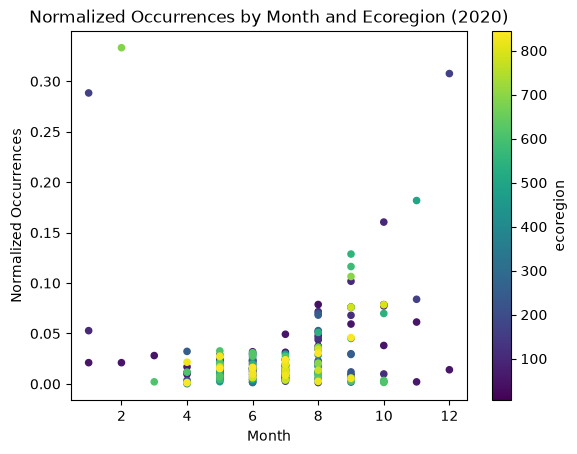

In [ ]:
### create a scatterplot
### reset the index to make it easier to work with then plot
occurrence_df.reset_index().plot.scatter(
    x = 'month',
    y = 'norm_occurrences',
    c = 'ecoregion',
    ylabel = 'Normalized Occurrences',
    xlabel = 'Month',
    title = 'Normalized Occurrences by Month and Ecoregion (2020)'
)

> This scatterplot shows us the normalized occurrences of Arctic Tern by month and ecoregion. We can see that at the start of the year, Arctic Tern are seen in 3 main ecoregions which are located near the poles. As the year goes on and we move towards summer in the northern hemisphere, we see Arctic Tern in a wider range of ecoregions in both polar and temperate regions, with low occurrences across ecoregions. Moving from June to October, we see a decrease in the number of ecoregions and an increase in the normalized occurrences in each of these ecoregions. From October to December, we see a gradual decrease in the number of ecoregions, with most occurrences shifting to polar regions, and the normalized occurrences in the few regions with Arctic Terns gradually increased as the number of ecoregions decreased.

In [11]:
### simplify the geometry to speed up processing
ecoreg_gdf.geometry = ecoreg_gdf.simplify(

    ### set tolerance level and don't preserve topology
    0.05, preserve_topology = False
)

### change the CRS to Mercator for mapping
ecoreg_gdf = ecoreg_gdf.to_crs(ccrs.Mercator())

In [12]:
### prep the data, then combine the occurrence data with the ecoregions

### rename columns in ecoregID to match occurrence_df
ecoreg_gdf = ecoreg_gdf.rename(columns = {'OBJECTID': 'ecoregion'})

### make ecoreg ID the index for merge with occurrence_df
ecoreg_gdf = ecoreg_gdf.set_index('ecoregion')

### join the occurrences with the plotting GeoDataFrame
occurrence_gdf = ecoreg_gdf.join(occurrence_df)

In [13]:
### activate panel and hvplot extensions you'll need for the interactive plot
pn.extension()
hv.extension("bokeh")

In [24]:
### get the plot bounds
xmin, ymin, xmax, ymax = occurrence_gdf.total_bounds

### define the slider widget
slider = pn.widgets.DiscreteSlider(
    name = 'month', 
    options = {calendar.month_name[i]: i for i in range(1, 13)}
)

### make the basemap tile object
carto_tiles = hv.Tiles(
    ("https://basemaps.cartocdn.com/rastertiles/voyager/{Z}/{X}/{Y}.png"
    "?key=cb1_446c_1_8946b413de0ace50f732dbf1"),
    name = "CARTO"
)

### plot occurrence by ecoregion and month
migration_plot = (
    occurrence_gdf
    .hvplot(
        ### color by # of veeries
        c = 'norm_occurrences',

        ### group by month
        groupby = 'month',

        ### use background tiles
        geo = True, crs = ccrs.Mercator(),

        ### add the basemap
        tiles = carto_tiles,

        ### add a title
        title = "Arctic Tern migration from January through December of 2020",

        ### set plot boundaries
        xlim = (xmin, xmax), ylim = (ymin, ymax),

        ### set dimensions of map
        frame_height = 600,
        frame_width = 900,

        ### put the widget at the bottom of the map
        widget_location = 'bottom',
        colorbar = True,
        widgets = {'month': slider}
    )
)

### wrap  plot in the Panel layout
interactive_migration_plot = pn.panel(migration_plot)

### make a path for your map to live
map_path = os.path.join(data_dir, "migration_plot.html")

### export the map as an .html file
migration_plot.save(
    map_path,
    embed = True,
    resources = "inline",
)

### check it out
interactive_migration_plot

BokehModel(combine_events=True, render_bundle={'docs_json': {'41ffc558-b2b1-47fe-9c59-7ce1c5975822': {'version…

## Interactive Map
> Another way of visualizing the data seen in the previously shown scatterplot is in an interactive map. Here, we show the spatial distribution of Arctic Tern by month. This gives us insight into some of the trends in migration patterns that may exist for this species. 

## Limitations
> Some limitations that are important to note include the fact that the occurrence data used here is limited by observations.

## Bibliography

> Morten, J. M., Buchanan, P. J., Egevang, C., Glissenaar, I. A., Maxwell, S. M., Parr, N., Screen, J. A., Vigfusdottir, F., Vogt-Vincent, N., S., Williams, D. A. (2023) Global warming and arctic terns: Estimating climate change impacts on the world's longest migration. Global Change Biology. https://doi.org/10.1111/gbc.16891
>
>Alerstam, T., Backman, J., Gronroos, J., Olofsson, P., Strandberg, R. (2019) Hypotheses and tracking results about the longest migration: The case of the arctic tern. Ecology and Evolution. https://doi.org/10.1002/ece3.5459

In [19]:
!jupyter nbconvert --to html 06-portfolio-post.ipynb

[NbConvertApp] Converting notebook 06-portfolio-post.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 445945 bytes to 06-portfolio-post.html
